# Solutions to the exercises of Chapter 5

Sample solutions for [Chapter 5, Transient conduction](../../notebooks/part1_conduction/05_transient.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import reference, transient
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference, transient
from engtransport.plotting import panel_label, use_style

use_style()


def centre(geom, Fo, Bi):
    """Centre temperature theta from the series (5.5)-(5.7)."""
    return transient.transient_1d_series(np.array([0.0]), Fo, Bi, geom, n_modes=15)["theta_star"][0]

## Exercise 1. A thermocouple

For a sphere $V/A = R/3$, so $\tau = \rho c R/3h$ and $\mathrm{Bi}_c = hR/3k$. The reading is
within 1 % of a sudden change when $e^{-t/\tau} = 0.01$, after $t = \tau\ln 100 = 4.6\,\tau$.

In [2]:
D_tc, rho_tc, c_tc, k_tc = 0.5e-3, 8500.0, 400.0, 20.0
Lc = D_tc / 6
for medium, h in (("air", 100.0), ("water", 2000.0)):
    tau = rho_tc * c_tc * Lc / h
    print(f"{medium:5s}: Bi_c = {h * Lc / k_tc:.1e}, time constant {tau:.3f} s, within 1 % after {tau * math.log(100):.2f} s")

air  : Bi_c = 4.2e-04, time constant 2.833 s, within 1 % after 13.05 s
water: Bi_c = 8.3e-03, time constant 0.142 s, within 1 % after 0.65 s


$\mathrm{Bi}_c$ is below $10^{-2}$ in both cases, so the junction is isothermal and the
lumped model is exact for practical purposes. The junction answers in a few seconds in
air and in a tenth of a second in water. In air its time constant is set by $h$, not by
the junction: to read a fluctuating air temperature, use a finer wire, and do not trust a
reading taken sooner than five time constants after a change.

## Exercise 2. Boiling an egg

The egg is a sphere with $\mathrm{Bi} = hR/k = 41$, nearly a sphere whose surface is at
100 °C at once. The centre must reach $\theta = (65 - 100)/(5 - 100) = 0.368$:

In [3]:
k_egg, rho_egg, c_egg, h_w = 0.55, 1035.0, 3300.0, 1000.0
alpha_egg = k_egg / (rho_egg * c_egg)
theta_target = (65.0 - 100.0) / (5.0 - 100.0)
times = {}
for D in (0.045, 0.050):
    R = D / 2
    Bi = h_w * R / k_egg
    Fo = brentq(lambda F: centre("sphere", F, Bi) - theta_target, 0.01, 2.0)
    times[D] = Fo * R**2 / alpha_egg
    print(f"{1e3 * D:.0f} mm egg: Bi = {Bi:.0f}, Fo = {Fo:.3f}, centre at 65 C after {times[D] / 60:.1f} min")
print(f"ratio {times[0.050] / times[0.045]:.2f} (diameter ratio squared {(50 / 45) ** 2:.2f})")

45 mm egg: Bi = 41, Fo = 0.179, centre at 65 C after 9.4 min
50 mm egg: Bi = 45, Fo = 0.178, centre at 65 C after 11.5 min
ratio 1.23 (diameter ratio squared 1.23)


The 45 mm egg needs 9.4 minutes for its yolk to start setting, and the 50 mm egg 11.5
minutes, 23 % longer. Because Bi is large, the time is set by conduction inside the egg,
$t \propto R^2/\alpha$, and grows almost as the square of the size. An egg straight from the
refrigerator needs a few minutes more than one at room temperature, which is why recipes
disagree.

## Exercise 3. A short cylinder

For a cylinder of radius $R$ and length $2L$, the solution of the heat equation with a
convective surface is the product $\theta = \theta_{\rm slab}(z, t)\,\theta_{\rm cyl}(r, t)$:
each factor obeys its own one-dimensional equation and surface condition, and the product
satisfies the two-dimensional equation and all the surface conditions.

In [4]:
k_st, rho_c = 30.0, 7800.0 * 600.0
alpha = k_st / rho_c
h_oil, T_oil, T_i = 1000.0, 60.0, 850.0
R = L_half = 0.05
theta_500 = (500.0 - T_oil) / (T_i - T_oil)
Bi = h_oil * R / k_st
billet = lambda t: centre("slab", alpha * t / L_half**2, h_oil * L_half / k_st) * centre("cylinder", alpha * t / R**2, Bi)
long_bar = lambda t: centre("cylinder", alpha * t / R**2, Bi)
t_billet = brentq(lambda t: billet(t) - theta_500, 1.0, 1000.0)
t_long = brentq(lambda t: long_bar(t) - theta_500, 1.0, 1000.0)
print(f"centre at 500 C: billet 100 x 100 mm after {t_billet:.0f} s, long bar of 100 mm after {t_long:.0f} s")

centre at 500 C: billet 100 x 100 mm after 116 s, long bar of 100 mm after 145 s


The centre of the billet reaches 500 °C after 116 s, against 145 s for a long bar of the
same diameter: the two ends add surface and shorten the time by a fifth.

## Exercise 4. A boiling quench

boiling, h(T_s)   : centre t8/5 =  16.3 s, centre at 500 C after  31.0 s


constant h = 5000 : centre t8/5 =  15.3 s, centre at 500 C after  24.8 s
film boiling ends (surface at 600 C) after 12.2 s


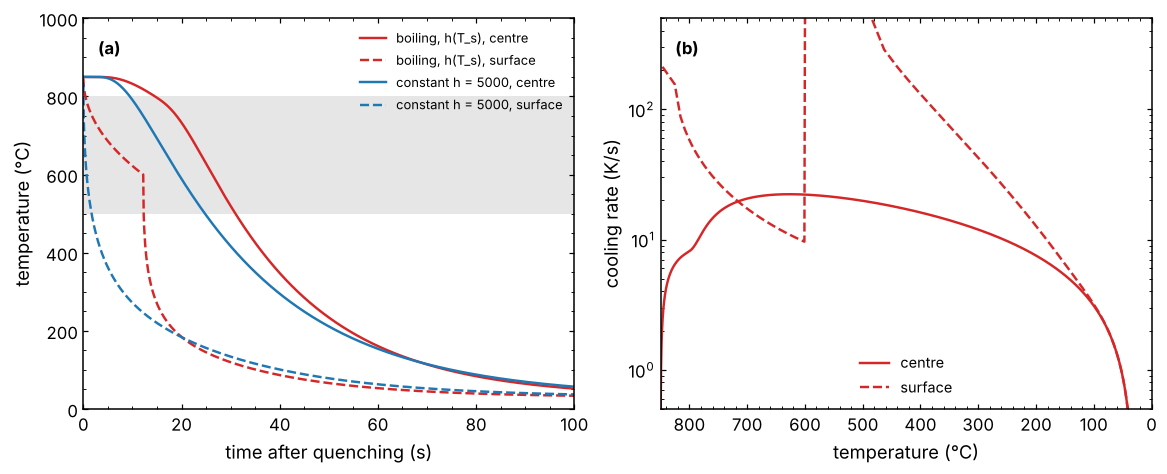

In [5]:
R_bar, T_water = 0.025, 30.0
h_boil = lambda T_surface: 1000.0 if T_surface > 600.0 else 8000.0
runs = {"boiling, h(T_s)": h_boil, "constant h = 5000": 5000.0}
results = {}
for name, h in runs.items():
    out = reference.transient_conduction_fv(R_bar, k_st, rho_c, h, T_water, 850.0, "cylinder", n_cells=100,
                                            t_end=150.0, n_steps=15000, save_every=10)
    results[name] = out
    t, Tc = out["t"], out["T"][:, 0]
    t8 = t[np.argmax(Tc < 800)]
    t5 = t[np.argmax(Tc < 500)]
    print(f"{name:18s}: centre t8/5 = {t5 - t8:5.1f} s, centre at 500 C after {t5:5.1f} s")
t, Ts = results["boiling, h(T_s)"]["t"], results["boiling, h(T_s)"]["T_surface"]
print(f"film boiling ends (surface at 600 C) after {t[np.argmax(Ts < 600)]:.1f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for (name, out), color in zip(results.items(), ("C3", "C0")):
    ax1.plot(out["t"], out["T"][:, 0], color, label=f"{name}, centre")
    ax1.plot(out["t"], out["T_surface"], color + "--", label=f"{name}, surface")
ax1.axhspan(500, 800, color="0.9", lw=0)
ax1.set_xlabel("time after quenching (s)")
ax1.set_ylabel("temperature (°C)")
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 1000)
ax1.legend(loc="upper right", fontsize=8.5)
panel_label(ax1, "(a)")

out = results["boiling, h(T_s)"]
rate = -np.gradient(out["T"][:, 0], out["t"])
rate_s = -np.gradient(out["T_surface"], out["t"])
ax2.plot(out["T"][:, 0], rate, "C3", label="centre")
ax2.plot(out["T_surface"], rate_s, "C3--", label="surface")
ax2.set_xlabel("temperature (°C)")
ax2.set_ylabel("cooling rate (K/s)")
ax2.set_xlim(850, 0)
ax2.set_yscale("log")
ax2.set_ylim(0.5, 500)
ax2.legend(loc="lower center")
panel_label(ax2, "(b)")
plt.show()

**Figure S5.1.** (a) Temperatures of a 50 mm steel bar quenched in water, with a heat
transfer coefficient that jumps from 1000 to 8000 W/(m² K) when the surface cools below
600 °C, compared with a constant 5000 W/(m² K). (b) Cooling rates at the centre and the
surface against the local temperature, for the boiling quench.

The vapour film holds the surface above 600 °C for the first 12 s, during which the bar
cools slowly and fairly uniformly. When the film collapses, the surface temperature drops
by hundreds of kelvin within a few seconds (Figure S5.1b), the steep jump that quench
curves measured with thermocouples show. The centre cools through 800–500 °C in 16 s,
close to the 15 s found with the constant average $h$, but it reaches 500 °C later, after
31 s instead of 25 s, because the film stage delays the start. The film stage is what makes oil and water quenches
hard to predict, and why quenchants are agitated or contain additives that shorten it.